In [3]:
import numpy as np #PRIMARY GOAL: RANDOM NUMBER GENERATION
import matplotlib.pyplot as plt #VISUALIZATIONS
from matplotlib.animation import FuncAnimation #ANIMATION
from IPython.display import HTML #RENDERS ANIMATED SIMULATION DIRECTLY AS AN INLINE HTML5 VIDEO
from scipy.stats import gaussian_kde #KERNEL DENSITY ESTIMATION
import warnings 
warnings.filterwarnings('ignore') #SUPPRESSES WARNING MESSAGES THAT JUPYTER MIGHT OUTPUT

In [4]:
#PARAMETERS
population_size=5000
distribution='exponential'
scale_beta= 2 #LET SCALE=2 FOR SIMULATION PURPOSES
n_samples=300 #NUMBER OF SAMPLES DRAWN FROM THE POPULATION

sample_sizes=list( range(50, 5001, 50)) #SAMPLE SIZE FROM 50 TO 5000


In [5]:
#GENERATE THE POPULATION
np.random.seed(42) #RESTRICT THE RANDOM GENERATION FROM CHANGING FOR EVERY RUN
population= np.random.exponential (scale=scale_beta, size=population_size)

#TRUE POPULATION PARAMETERS
population_mean=np.mean(population)
population_std=np.std(population)

print(f"Population Size: {population_size}")
print(f"Population Mean: {population_mean:.4f}")
print(f"Population Std: {population_std:.4f}")

Population Size: 5000
Population Mean: 1.9795
Population Std: 1.9739


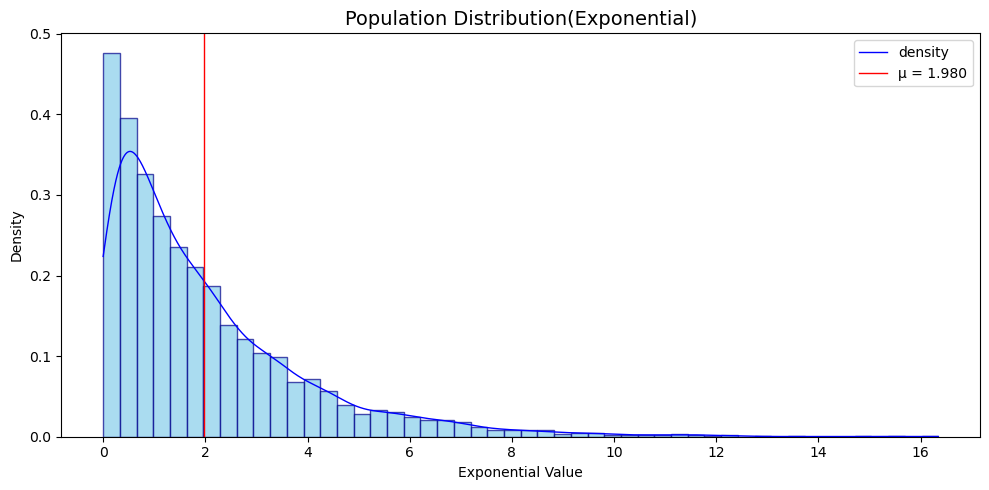

In [6]:
#POPULATION DISTRIBUTION (EXPONENTIAL DISTRIBUTION)
fig, ax = plt.subplots(figsize=(10,5)) #INITIALIZING THE PLOTTING ENVIRONMENT

#HISTOGRAM
ax.hist(population, bins=50, density=True, alpha=0.7, color='skyblue', edgecolor='darkblue')

#DENSITY LINE
#WE'RE ESTIMATING THE PROBABILITY DENSITY FUNCTION OF THE POPULATION
#HISTOGRAM SHOWS RAW DATA, KDE SHOWS SMOOTHED VERSION
#CREATE A KDE FUNCTION FROM THE POPULATION
kde=gaussian_kde(population)
#WE'RE ESTIMATING THE PROBABILITY DENSITY FUNCTION OF THE X_VALUES
x_range=np.linspace(population.min(), population.max(), 5000)
ax.plot(x_range, kde(x_range), 'r-', linewidth=1, label='density', color='blue')



ax.axvline(population_mean, color='red', linewidth=1, label=f'μ = {population_mean:.3f}')
ax.set_xlabel('Exponential Value')
ax.set_ylabel('Density')
ax.set_title(f'Population Distribution({distribution.capitalize()})', fontsize=14)

plt.tight_layout()
ax.legend()

plt.savefig('../outputs/figures/population_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


In [7]:
#RUN SIMULATION
print("Running simulation...")
print(f"Testing sample sizes: {len(sample_sizes)} sample sizes")
print(f"Drawing {n_samples} samples for each sample size")

sample_means=[] #MEAN OF ALL SAMPLE MEANS FOR EACH SAMPLE SIZE
empirical_errors=[] #EMPIRICAL STANDARD ERROR
theoretical_errors=[] #sigma/ sqrt(n)

for n in sample_sizes:
    #DRAW N_SAMPLES OF SIZE N
    means_of_samples=[]
    for _ in range(n_samples): # n_samples=300
        #SAMPLING FROM THE POPULATION
        sample=np.random.choice(population, size=n, replace=True)
        means_of_samples.append(np.mean(sample))

    #FOR SAMPLING DISTRIBUTION PURPOSES, WE COMPUTE MEANS OF THOSE SAMPLE MEANS
    #AND OBSERVE THEM IN A SINGLE OBJECT
    sample_means.append(np.mean(means_of_samples))
    empirical_errors.append(np.std(means_of_samples, ddof=1 ))
    #ddof=0 USE THIS FOR A COMPLETE POPULATION
    #ddof=1 USE THIS FOR SAMPLES TO ESTIMATE POPULATION
    theoretical_errors.append(population_std/np.sqrt(n))


Running simulation...
Testing sample sizes: 100 sample sizes
Drawing 300 samples for each sample size


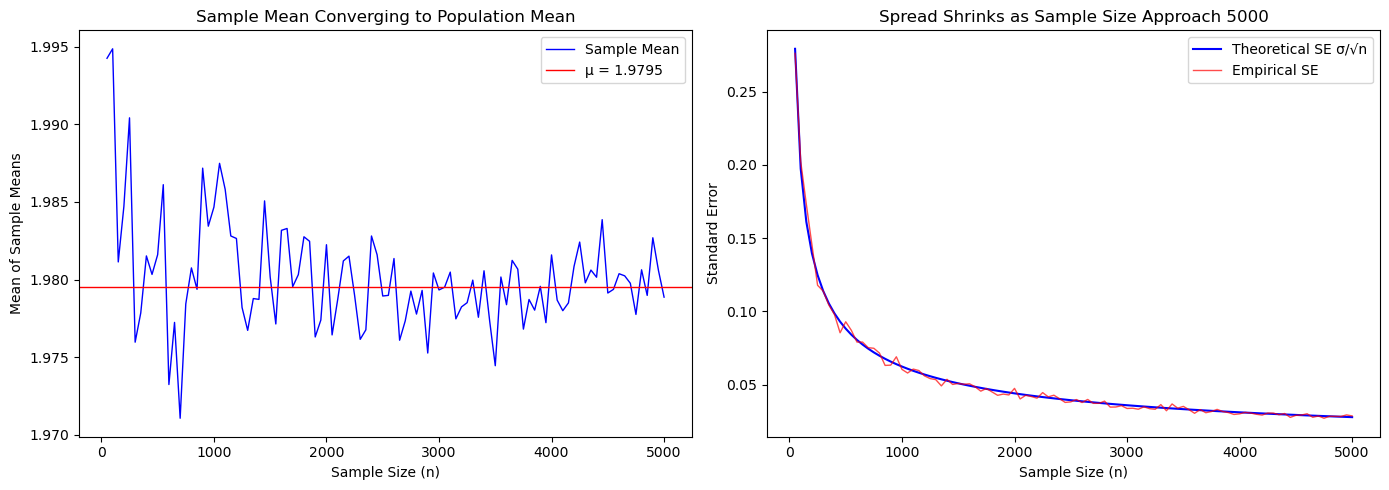

In [8]:
#CONVERGENCE PLOT
fig, (ax1, ax2)=plt.subplots(1,2, figsize=(14,5))

#PLOT1: SAMPLE MEAN CONVERGENCE TO TRUE POPULATION MEAN (μ)
ax1.plot(sample_sizes, sample_means,  'b-', linewidth=1, label='Sample Mean')
ax1.axhline(population_mean, color='red', linewidth=1, label=f'μ = {population_mean:.4f}')
ax1.set_title('Sample Mean Converging to Population Mean')
ax1.set_xlabel('Sample Size (n)')
ax1.set_ylabel('Mean of Sample Means')

#PLOT2: STANDARD ERROR DECAYS
ax2.plot(sample_sizes, theoretical_errors, 'g-', linewidth=1.5, label='Theoretical SE σ/√n', color='blue')
ax2.plot(sample_sizes,  empirical_errors, linewidth=1, label='Empirical SE', alpha=0.7, color='red')

ax2.set_xlabel('Sample Size (n)')
ax2.set_ylabel('Standard Error')
ax2.set_title('Spread Shrinks as Sample Size Approach 5000')

plt.tight_layout()
ax1.legend()
ax2.legend()
plt.savefig('../outputs/figures/convergence.png', dpi=150, bbox_inches='tight')
plt.show()


In [9]:
#ANIMATION
from matplotlib.animation import FuncAnimation

# Setup figure with two subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

# Initialize empty plots
line1, = ax1.plot([], [], 'b-', linewidth=2, label='sample mean')
line2, = ax2.plot([], [], 'b-', linewidth=2)

ax1.axhline(population_mean, color='red', linewidth=2, label=f'μ = {population_mean:.3f}')
ax1.set_xlim(50, max(sample_sizes))
ax1.set_xticks(range(50, 5001, 50)) 
ax1.set_ylim(1.960, 2.0)
ax1.set_xlabel('Sample Size (n)')
ax1.set_ylabel('Mean of Sample Means')
ax1.set_title('LLN: SAMPLE MEAN CONVERGES TO POPULATION MEAN')
ax1.legend(loc='lower right')
ax1.grid(alpha=0.3)

ax2.set_xlim(50, max(sample_sizes))
ax2.set_xticks(range(50, 5001, 50)) 
ax2.set_ylim(0, 0.24)
ax2.set_xlabel('Sample Size (n)')
ax2.set_ylabel('Standard Error (σ/√n)')
ax2.set_title('SPREAD SHRINKS AS n INCREASES')
ax2.grid(alpha=0.3)

# Store data for animation
x_data, y_data1, y_data2 = [], [], []

def update(frame):
    n_idx = frame
    n = sample_sizes[n_idx]
    
    # Update data
    x_data.append(n)
    y_data1.append(sample_means[n_idx])
    y_data2.append(theoretical_errors[n_idx])
    
    # Update lines
    line1.set_data(x_data, y_data1)
    line2.set_data(x_data, y_data2)
    
    # Update the lines (X-axis stays fixed to show the full convergence)
    line1.set_data(x_data, y_data1)
    line2.set_data(x_data, y_data2)
    
    return line1, line2

# Create animation
anim = FuncAnimation( fig, update, frames=len(sample_sizes), interval=50, blit=True, repeat=False)
plt.tight_layout()
#HTML(anim.to_jshtml(default_mode='once')) 

# Show animation
HTML(anim.to_jshtml())

# Save animation
anim.save('../outputs/figures/convergence_animation.gif', writer='pillow', fps=20)
print("Animation saved to outputs/figures/convergence_animation.gif")
# Prevent duplicate display
plt.close() 

[10/13/26 07:48:45] INFO     Animation.save using <class 'matplotlib.animation.HTMLWriter'>       ]8;id=11859898;file://c:\Users\tshep\anaconda3\envs\tshep_environment\lib\site-packages\matplotlib\animation.py\animation.py]8;;\:]8;id=11859899;file://c:\Users\tshep\anaconda3\envs\tshep_environment\lib\site-packages\matplotlib\animation.py#1040\1040]8;;\

[10/13/26 07:50:18] INFO     Animation.save using <class 'matplotlib.animation.PillowWriter'>     ]8;id=11859904;file://c:\Users\tshep\anaconda3\envs\tshep_environment\lib\site-packages\matplotlib\animation.py\animation.py]8;;\:]8;id=11859905;file://c:\Users\tshep\anaconda3\envs\tshep_environment\lib\site-packages\matplotlib\animation.py#1040\1040]8;;\

Animation saved to outputs/figures/convergence_animation.gif
